## SENTIMENT ANALYSIS EXMAPLE

In [7]:
from keras.datasets import imdb
import numpy as np

(trainset, trainlables), (testset, testlabels) = imdb.load_data(num_words = 10000)
word_index = imdb.get_word_index()

print(trainset.shape)
print(trainset[0])

# so here keras is doing all the hard work for me, it imports the data and assigns each word a number

(25000,)
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]


In [ ]:
# lets see if we can decode 

reverse_index = dict((v, k) for (k, v) in word_index.items()) 

def translate(list):
    r = " ".join([reverse_index.get(i-3, '?') for i in list])
    return r

In [19]:
print(translate(trainset[0]))

? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also ? to the two little boy's that played the ? of norman and paul they were just brilliant children are often left out of the ? list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done don't you thi

In [33]:
# Vectorize function

def vectorize(seqences, dimension = 10000):
    results = np.zeros((len(seqences),dimension))
    for i, seq in enumerate(seqences):
        results[i, seq] = 1
    return results

In [34]:
# apply vectorise

x_train = vectorize(trainset)
x_test = vectorize(testset)

y_train = np.asarray(trainlables).astype('float32') #keras expects nums to be floats instead of ints




In [35]:
# define the network 
from keras import models, layers

network = models.Sequential()  # Creates an empty network where layers are added one after another

network.add(
    layers.Dense(16, activation='relu', input_shape=(10000,))
)  # First hidden layer: 16 neurons using ReLU

network.add(
    layers.Dense(16, activation='relu')
)  # Second hidden layer: 16 neurons using ReLU

network.add(
    layers.Dense(1, activation='sigmoid')
)  # Output layer: 1 neuron using Sigmoid

/Users/hamidaziz/Documents/UoS/Year3/Deep Learning/workshops/wk3/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [36]:
# compile
network.compile(optimizer='rmsprop', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [37]:
# Train the network
hist = network.fit(
    x_train,
    y_train,
    epochs=10,      # Go through the full training dataset 10 times
    batch_size=512  # Update the network after every 512 training examples
)

# hist stores information about what happened during training
h_dict = hist.history

# Loss value recorded after each epoch
loss = h_dict['loss']

# Accuracy recorded after each epoch
acc = h_dict['accuracy']

Epoch 1/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7450 - loss: 0.5421
Epoch 2/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8988 - loss: 0.3192
Epoch 3/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9189 - loss: 0.2358
Epoch 4/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9320 - loss: 0.1953
Epoch 5/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9400 - loss: 0.1719
Epoch 6/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9500 - loss: 0.1498
Epoch 7/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9546 - loss: 0.1348
Epoch 8/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9606 - loss: 0.1197
Epoch 9/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9642 - loss: 0.1086
Epoch 10/10
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9697 - loss: 0.0974


In [38]:
print(acc)

[0.7449600100517273, 0.8988000154495239, 0.9188799858093262, 0.9319599866867065, 0.9399600028991699, 0.9499599933624268, 0.9546399712562561, 0.9605600237846375, 0.9641600251197815, 0.9697200059890747]


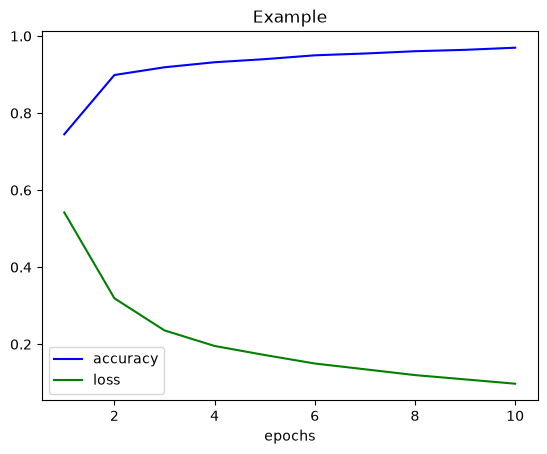

In [39]:
import matplotlib.pyplot as plt

xaxis = range(1, len(acc)+1)

plt.plot(xaxis,acc,'b', label = 'accuracy')
plt.plot(xaxis, loss, 'g', label = 'loss')
plt.xlabel('epochs')
plt.title('Example')
plt.legend()
plt.show()

## ILLUSTRATION OF VALDIATION SETS

when coming back to it work on the partial data set and hte edits to hist